# Неделя 24. n8n: основы workflow

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** построить validate/transform/load процесс, выполнить SQL idempotency и ошибки; импортировать готовые n8n workflows.

**Offline Python-эквивалент:** данные HTTP взяты из fixture, реального HTTP вызова в notebook нет. Экспорт n8n импортируется отдельно; действительный engine-run не заявлен.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_24_n8n_workflows"
DATA = WEEK / "datasets"
SEED = 124
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. Items, JSON и provenance

n8n передает items между nodes. В fixture есть повтор и ошибочные записи: успешный HTTP-код не делает содержимое качественным. Сначала исследуем поля и распределение.


,ticket_id,category,minutes_open
0,N101,access,120
1,N102,billing,35
2,N103,schedule,18
3,N101,access,120
4,N104,other,-5
5,,access,2
6,N105,other,240
7,N106,billing,45


,ticket_id,category,minutes_open
count,8,8,8.00000
unique,7,4,NaN
top,N101,access,NaN
freq,2,3,NaN
mean,NaN,NaN,71.87500
std,NaN,NaN,83.38797
min,NaN,NaN,-5.00000
25%,NaN,NaN,14.00000
50%,NaN,NaN,40.00000
75%,NaN,NaN,120.00000


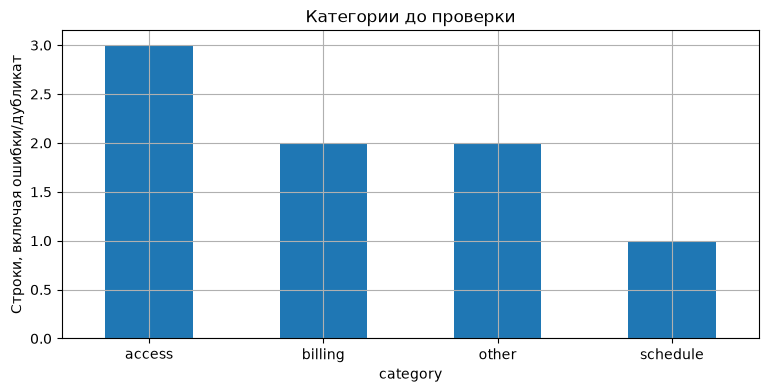

In [2]:
payload = json.loads((DATA / 'http_response_fixture.json').read_text(encoding='utf-8'))
raw = pd.DataFrame(payload['tickets'])
display(raw)
display(raw.describe(include='all'))
raw.category.value_counts().plot.bar(rot=0, title='Категории до проверки')
plt.ylabel('Строки, включая ошибки/дубликат'); plt.show()
assert len(raw) == 8


## 2. Validation перед трансформацией

Договоримся: ID=N+3 цифры, category из закрытого списка, minutes_open — неотрицательное целое. Ошибочную строку отправляем в отдельный список с причиной. Изменять -5 на 5 молча нельзя.


In [3]:
import re
def validate_item(item):
    if not isinstance(item, dict):
        return 'not_an_object'
    if not re.fullmatch(r'N\d{3}', str(item.get('ticket_id', ''))):
        return 'invalid_id'
    if item.get('category') not in {'access', 'billing', 'schedule', 'other'}:
        return 'invalid_category'
    value = item.get('minutes_open')
    if type(value) is not int or value < 0:
        return 'invalid_minutes'
    return None
accepted, rejected = [], []
for item in payload['tickets']:
    error = validate_item(item)
    if error:
        rejected.append({'item': item, 'error': error})
    else:
        accepted.append(item)
assert len(accepted) == 6 and len(rejected) == 2
display(pd.DataFrame(rejected))


,item,error
0,"{'ticket_id': 'N104', 'category': 'other', 'mi...",invalid_minutes
1,"{'ticket_id': '', 'category': 'access', 'minut...",invalid_id


## 3. Трансформация и deduplication

Для данного fixture дубликат идентичен, поэтому оставим одну запись по ticket_id. В реальном потоке конфликтующие версии требуют timestamp/version, а не произвольного keep-first. Priority задается наблюдаемым правилом.


In [4]:
unique = {item['ticket_id']: item.copy() for item in accepted}
transformed = []
for item in unique.values():
    item['priority'] = 'high' if item['minutes_open'] >= 60 else 'normal'
    transformed.append(item)
clean_df = pd.DataFrame(transformed)
assert len(clean_df) == 5 and clean_df.ticket_id.is_unique
display(clean_df)


,ticket_id,category,minutes_open,priority
0,N101,access,120,high
1,N102,billing,35,normal
2,N103,schedule,18,normal
3,N105,other,240,high
4,N106,billing,45,normal


## 4. Настоящая локальная SQLite-загрузка

PRIMARY KEY защищает уникальность. UPSERT делает повторную обработку одинакового события идемпотентной: количество строк не растет после повторения. Это свойство записи, не гарантия exactly-once всей системы.


In [5]:
import sqlite3
db = sqlite3.connect(':memory:')
db.execute('CREATE TABLE tickets (ticket_id TEXT PRIMARY KEY, category TEXT, minutes_open INTEGER CHECK(minutes_open>=0), priority TEXT)')
def load_rows(rows):
    with db:
        db.executemany('INSERT INTO tickets VALUES (?, ?, ?, ?) ON CONFLICT(ticket_id) DO UPDATE SET '
                       'category=excluded.category, minutes_open=excluded.minutes_open, priority=excluded.priority',
                       [(r['ticket_id'], r['category'], r['minutes_open'], r['priority']) for r in rows])
load_rows(transformed)
first_count = db.execute('SELECT COUNT(*) FROM tickets').fetchone()[0]
load_rows(transformed)
second_count = db.execute('SELECT COUNT(*) FROM tickets').fetchone()[0]
assert first_count == second_count == 5
print('После первого/второго run:', first_count, second_count)


После первого/второго run: 5 5


## 5. SQL-аналитика результата

Теперь агрегируем только проверенные записи. Сравним среднюю и максимальную длительность по категориям. Синтетические числа не доказывают, что какая-либо служба реально работает медленнее.


,category,n,avg_minutes,max_minutes
0,access,1,120.0,120
1,billing,2,40.0,45
2,other,1,240.0,240
3,schedule,1,18.0,18


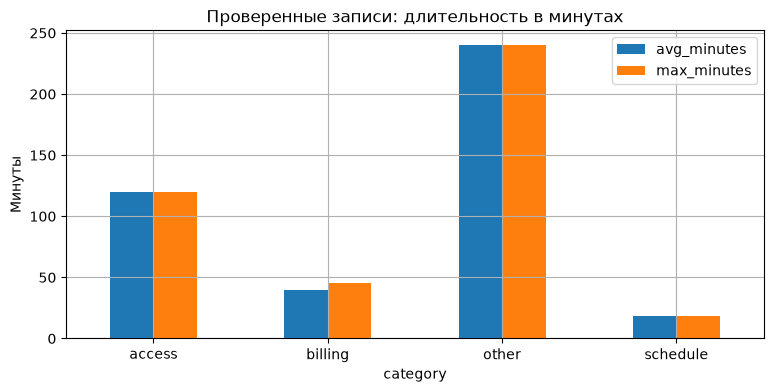

In [6]:
report = pd.read_sql_query('SELECT category, COUNT(*) AS n, AVG(minutes_open) AS avg_minutes, '
                           'MAX(minutes_open) AS max_minutes FROM tickets GROUP BY category', db)
display(report)
report.plot.bar(x='category', y=['avg_minutes', 'max_minutes'], rot=0)
plt.title('Проверенные записи: длительность в минутах'); plt.ylabel('Минуты'); plt.show()


## 6. Параметры SQL

Запрос отделен от пользовательского значения. Строка с SQL injection остается значением фильтра, а не командой. Параметры не позволяют безопасно подставлять произвольные имена таблиц — такие имена должны быть фиксированы или в allowlist.


In [7]:
selected = pd.read_sql_query('SELECT * FROM tickets WHERE category = ?', db, params=('billing',))
injection_result = db.execute('SELECT COUNT(*) FROM tickets WHERE category = ?',
                              ("billing' OR 1=1--",)).fetchone()[0]
assert injection_result == 0 and len(selected) == 2
display(selected)


,ticket_id,category,minutes_open,priority
0,N102,billing,35,normal
1,N106,billing,45,normal


## 7. Транзакция и rollback

Если пачка содержит невалидную строку, constraint останавливает запись, и transaction откатывает предыдущую запись этой пачки. Нельзя ловить исключение внутри transaction и случайно коммитить половину данных.


In [8]:
before = db.execute('SELECT COUNT(*) FROM tickets').fetchone()[0]
try:
    with db:
        db.execute('INSERT INTO tickets VALUES (?, ?, ?, ?)', ('N900', 'other', 1, 'normal'))
        db.execute('INSERT INTO tickets VALUES (?, ?, ?, ?)', ('N901', 'other', -1, 'normal'))
except sqlite3.IntegrityError:
    pass
assert db.execute('SELECT COUNT(*) FROM tickets').fetchone()[0] == before
assert db.execute('SELECT COUNT(*) FROM tickets WHERE ticket_id = ?', ('N900',)).fetchone()[0] == 0
print('Rollback отменил всю ошибочную пачку.')


Rollback отменил всю ошибочную пачку.


## 8. Аналитика ошибок и наблюдаемость

Статусы accepted/rejected/duplicate описывают разные вещи. Запишем счетчики без сохранения произвольных секретных payloads. В n8n Executions помогает увидеть ошибочный узел; Error Trigger выносит обработку в отдельный workflow.


In [9]:
metrics = {'input_rows': len(raw), 'rejected_rows': len(rejected),
           'duplicate_rows': len(accepted)-len(transformed), 'loaded_rows': len(transformed)}
assert metrics['input_rows'] == sum(metrics[k] for k in ['rejected_rows', 'duplicate_rows', 'loaded_rows'])
display(pd.Series(metrics))
db.close()


input_rows        8
rejected_rows     2
duplicate_rows    1
loaded_rows       5
dtype: int64

## 9. Структурная проверка n8n export

Читаем JSON workflow, проверяем имена узлов, связи и отсутствие credentials. Это полезная проверка файлов, но не замена импортированному engine-run. Runtime может потребовать выбор модели, credential или обновление версии узла.


In [10]:
workflow = json.loads((WEEK / 'practice' / 'n8n_offline_fixture.json').read_text())
names = {node['name'] for node in workflow['nodes']}
assert len(names) == len(workflow['nodes']) and workflow['active'] is False
for source, outputs in workflow['connections'].items():
    assert source in names
    for branches in outputs.values():
        for edges in branches:
            for edge in edges:
                assert edge['node'] in names
assert all('credentials' not in node for node in workflow['nodes'])
display(pd.DataFrame([{'node': n['name'], 'type': n['type']} for n in workflow['nodes']]))


,node,type
0,Manual Start,n8n-nodes-base.manualTrigger
1,Synthetic Items,n8n-nodes-base.code
2,Validate and Transform,n8n-nodes-base.code
3,Summary,n8n-nodes-base.code


## 10. Настоящий n8n run

Начните с no-credentials workflow, затем HTTP к локальному fixture server и read-only Postgres extension. Отдельный N8N_LAB.md содержит import, адреса для Docker и проверку результатов. Не подключайте реальные рассылки к учебному потоку.


In [11]:
print({'python_sqlite': 'passed', 'n8n_engine': 'not_run', 'http_network': 'not_run', 'postgres_live': 'not_run'})


{'python_sqlite': 'passed', 'n8n_engine': 'not_run', 'http_network': 'not_run', 'postgres_live': 'not_run'}


## Источники и следующий шаг

- [n8n: import and export](https://docs.n8n.io/build/manage-workflows/export-and-import.md)
- [n8n: HTTP Request](https://docs.n8n.io/integrations/builtin/core-nodes/n8n-nodes-base.httprequest/)
- [n8n: Postgres query parameters](https://docs.n8n.io/integrations/builtin/app-nodes/n8n-nodes-base.postgres/)
- [n8n: error workflows](https://docs.n8n.io/build/flow-logic/handle-errors-gracefully.md)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
